# Tech Challenge FIAP - Análise exploratória do NPS

Este notebook investiga quais aspectos da jornada estão mais associados à nota de satisfação.
A análise é descritiva: associação não significa causalidade.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

## 1. Leitura da base

In [2]:
base_path = Path("../Banco_de_dados/Base_NPS.csv")
df = pd.read_csv(base_path)
print(f"Linhas: {df.shape[0]:,}".replace(",", "."))
print(f"Colunas: {df.shape[1]}")
df.head()

Linhas: 2.500
Colunas: 19


,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9


## 2. Verificações iniciais

In [3]:
checagem = pd.Series({
    "valores ausentes": int(df.isna().sum().sum()),
    "customer_id duplicados": int(df["customer_id"].duplicated().sum()),
    "order_id duplicados": int(df["order_id"].duplicated().sum()),
})
checagem

valores ausentes          0
customer_id duplicados    0
order_id duplicados       0
dtype: int64

In [4]:
df["nps_score"].describe().round(2)

count    2500.00
mean        4.38
std         2.51
min         0.00
25%         2.60
50%         4.40
75%         6.10
max        10.00
Name: nps_score, dtype: float64

`nps_score` é uma nota individual de 0 a 10, e não o índice agregado de NPS da empresa.
Para a análise operacional, um registro abaixo de 7 é tratado como detrator.

In [5]:
df["detrator_operacional"] = (df["nps_score"] < 7).astype(int)
distribuicao = df["detrator_operacional"].value_counts().sort_index().rename(
    index={0: "nota 7 ou mais", 1: "nota abaixo de 7"}
)
pd.DataFrame({
    "registros": distribuicao,
    "percentual": (distribuicao / len(df) * 100).round(2),
})

,registros,percentual
detrator_operacional,,
nota 7 ou mais,391,15.64
nota abaixo de 7,2109,84.36


## 3. Relação entre variáveis numéricas e satisfação

In [6]:
numericas = df.select_dtypes(include="number").columns.drop("detrator_operacional")
pearson = df[numericas].corr(method="pearson")["nps_score"].drop("nps_score")
spearman = df[numericas].corr(method="spearman")["nps_score"].drop("nps_score")
correlacoes = pd.concat([pearson, spearman], axis=1)
correlacoes.columns = ["Pearson", "Spearman"]
correlacoes.reindex(pearson.abs().sort_values(ascending=False).index).head(10).round(3)

,Pearson,Spearman
delivery_delay_days,-0.597,-0.586
repeat_purchase_30d,0.570,0.489
csat_internal_score,0.564,0.561
complaints_count,-0.497,-0.490
customer_service_contacts,-0.351,-0.336
resolution_time_days,-0.191,-0.190
freight_value,-0.041,-0.040
order_value,0.037,0.036
delivery_attempts,0.028,0.026
discount_value,0.025,0.012


As maiores associações negativas aparecem em atraso, reclamações, contatos com o atendimento e tempo de resolução.
Recompra e CSAT são úteis na EDA, mas não entram no modelo porque podem estar disponíveis somente depois da experiência.

In [7]:
atraso = df.groupby("delivery_delay_days").agg(
    nota_media=("nps_score", "mean"),
    detratores=("detrator_operacional", "mean"),
    registros=("nps_score", "size"),
)
atraso["detratores"] = atraso["detratores"] * 100
atraso.head(7).round(2)

,nota_media,detratores,registros
delivery_delay_days,,,
0,6.86,51.62,277
1,5.55,73.98,615
2,4.58,87.93,646
3,3.44,96.76,525
4,2.44,99.26,270
5,1.48,100.00,116
6,1.10,100.00,34


In [8]:
reclamacoes = df.groupby("complaints_count").agg(
    nota_media=("nps_score", "mean"),
    detratores=("detrator_operacional", "mean"),
    registros=("nps_score", "size"),
)
reclamacoes["detratores"] = reclamacoes["detratores"] * 100
reclamacoes.round(2)

,nota_media,detratores,registros
complaints_count,,,
0,8.52,17.39,23
1,7.77,30.33,122
2,6.05,65.34,277
3,4.91,81.66,507
4,4.22,89.83,600
5,3.65,94.59,444
6,3.06,97.37,266
7,2.81,97.04,169
8,2.07,100.00,63


In [9]:
contatos = df.groupby("customer_service_contacts").agg(
    nota_media=("nps_score", "mean"),
    registros=("nps_score", "size"),
)
contatos.round(2)

,nota_media,registros
customer_service_contacts,,
0,5.54,554
1,4.66,816
2,4.12,640
3,3.20,314
4,2.65,132
5,2.24,34
6,0.74,7
7,1.20,3


In [10]:
recompra = df.groupby("repeat_purchase_30d")["nps_score"].agg(["mean", "count"])
recompra.index = ["sem recompra", "com recompra"]
recompra.round(2)

,mean,count
sem recompra,3.94,2282
com recompra,9.01,218


## 4. Pontos de ruptura

In [11]:
comparacoes = pd.DataFrame({
    "comparação": ["0 para 1 dia de atraso", "1 para 2 reclamações"],
    "queda na nota média": [
        atraso.loc[1, "nota_media"] - atraso.loc[0, "nota_media"],
        reclamacoes.loc[2, "nota_media"] - reclamacoes.loc[1, "nota_media"],
    ],
    "aumento de detratores (p.p.)": [
        atraso.loc[1, "detratores"] - atraso.loc[0, "detratores"],
        reclamacoes.loc[2, "detratores"] - reclamacoes.loc[1, "detratores"],
    ],
})
comparacoes.round(2)

,comparação,queda na nota média,aumento de detratores (p.p.)
0,0 para 1 dia de atraso,-1.31,22.36
1,1 para 2 reclamações,-1.72,35.02


In [12]:
def bootstrap_diferenca(grupo_a, grupo_b, repeticoes=10_000, seed=42):
    rng = np.random.default_rng(seed)
    diferencas = []
    for _ in range(repeticoes):
        media_a = rng.choice(grupo_a, len(grupo_a), replace=True).mean()
        media_b = rng.choice(grupo_b, len(grupo_b), replace=True).mean()
        diferencas.append(media_b - media_a)
    return np.quantile(diferencas, [0.025, 0.975])

ic_atraso = bootstrap_diferenca(
    df.loc[df["delivery_delay_days"] == 0, "nps_score"].to_numpy(),
    df.loc[df["delivery_delay_days"] == 1, "nps_score"].to_numpy(),
)
ic_reclamacoes = bootstrap_diferenca(
    df.loc[df["complaints_count"] == 1, "nps_score"].to_numpy(),
    df.loc[df["complaints_count"] == 2, "nps_score"].to_numpy(),
)
print("IC 95% - 0 para 1 dia de atraso:", np.round(ic_atraso, 2))
print("IC 95% - 1 para 2 reclamações:", np.round(ic_reclamacoes, 2))

IC 95% - 0 para 1 dia de atraso: [-1.6  -1.02]
IC 95% - 1 para 2 reclamações: [-2.07 -1.37]


## 5. Qualidade dos dados

In [13]:
casos_financeiros = df["discount_value"] > df["order_value"]
print("Desconto maior que o valor do pedido:", int(casos_financeiros.sum()))
print("Atraso maior que o prazo informado:", int((df["delivery_delay_days"] > df["delivery_time_days"]).sum()))

Desconto maior que o valor do pedido: 35
Atraso maior que o prazo informado: 121


Os 35 casos de desconto maior que o pedido foram mantidos na análise principal, pois a base não traz regra suficiente para confirmar erro.

Neste projeto, `delivery_time_days` é tratado como prazo estimado, conforme o esclarecimento recebido do professor. Assim, um atraso maior que esse prazo não é classificado como inconsistência. Essa interpretação deve continuar registrada porque o dicionário do PDF usa a expressão “tempo total de entrega”.

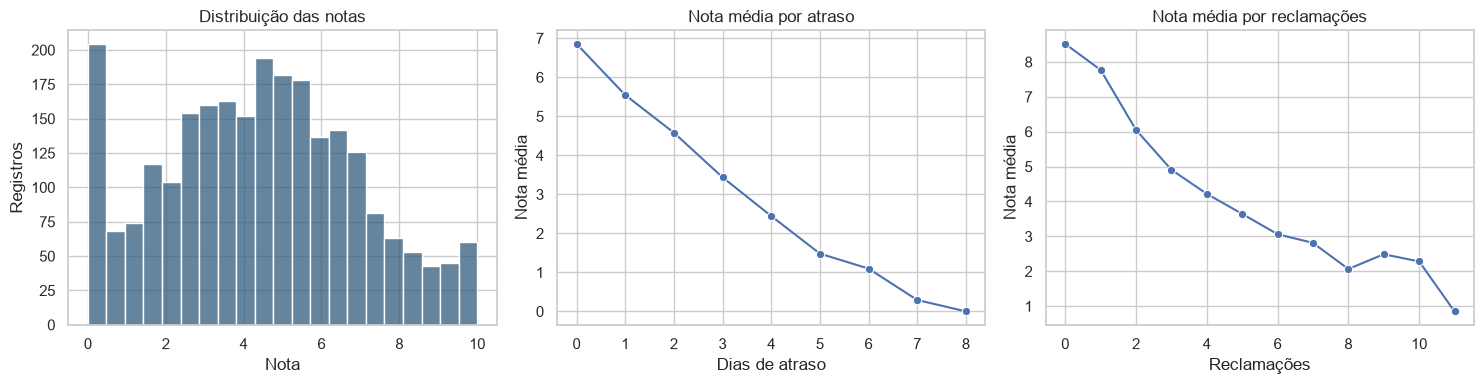

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df["nps_score"], bins=21, ax=axes[0], color="#315b7d")
axes[0].set(title="Distribuição das notas", xlabel="Nota", ylabel="Registros")

sns.lineplot(data=atraso.reset_index(), x="delivery_delay_days", y="nota_media", marker="o", ax=axes[1])
axes[1].set(title="Nota média por atraso", xlabel="Dias de atraso", ylabel="Nota média")

sns.lineplot(data=reclamacoes.reset_index(), x="complaints_count", y="nota_media", marker="o", ax=axes[2])
axes[2].set(title="Nota média por reclamações", xlabel="Reclamações", ylabel="Nota média")
plt.tight_layout()
plt.show()

## 6. Síntese para o negócio

In [15]:
resumo = {
    "nota média": round(df["nps_score"].mean(), 2),
    "registros abaixo de 7": f"{df['detrator_operacional'].mean() * 100:.2f}%",
    "queda de 0 para 1 dia de atraso": round(comparacoes.loc[0, "queda na nota média"], 2),
    "queda de 1 para 2 reclamações": round(comparacoes.loc[1, "queda na nota média"], 2),
}
pd.Series(resumo)

nota média                           4.38
registros abaixo de 7              84.36%
queda de 0 para 1 dia de atraso     -1.31
queda de 1 para 2 reclamações       -1.72
dtype: object

Na base analisada, a satisfação se diferencia mais pelos acontecimentos da jornada do que pelo perfil inicial do cliente. O primeiro dia de atraso e a passagem de uma para duas reclamações são faixas importantes para acompanhamento. Como não há datas dos eventos nem desenho experimental, os resultados não provam causalidade e não devem ser generalizados para toda a população da empresa.